# Mutual-Information Feature Selection + CatBoost / Random Forest / XGBoost

**Pipeline**
1. Load and clean data (mixed numeric + categorical features)
2. Stratified train/test split (**80 / 20**)
3. Feature selection with **Mutual Information** (computed on the training set only, since ANOVA F-test assumes numeric features and is unsuitable for mixed data types)
4. Build, tune (cross-validated) and test **CatBoost, Random Forest, XGBoost**
5. Compare Accuracy, Recall, F1 and ROC-AUC on the held-out test set

> Edit the **Configuration** cell (file path and target column) before running.

In [10]:
# !pip install catboost xgboost scikit-learn pandas numpy matplotlib seaborn

In [11]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.feature_selection import mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay,
                             classification_report)
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

RANDOM_STATE = 42

## 1. Configuration

In [12]:
DATA_PATH = "dataset/gallstone_cleaned.csv"     # <-- change
TARGET    = "gallstone_status"            # <-- change (name of the label column)
TEST_SIZE = 0.20                # 20% test set
CV_FOLDS  = 5
N_ITER    = 25                  # random-search iterations per model
MI_TOP_K  = None                # None = keep all features with MI > 0; or set an int, e.g. 15

## 2. Load data

In [13]:
df = pd.read_csv(DATA_PATH)           # use pd.read_excel for .xlsx
print(df.shape)
df.head()

(318, 34)


,gallstone_status,age,gender,comorbidity,cad,hypothyroidism,hyperlipidemia,dm,height,weight,...,hdl,triglyceride,ast,alt,alp,creatinine,gfr,crp,hgb,vitamin_d
0,0,50,0,0,0,0,0,0,185,92.8,...,40.0,134.0,20.0,22.0,87.0,0.82,112.47,0.0,16.0,33.0
1,0,47,0,1,0,0,0,0,176,94.5,...,43.0,103.0,14.0,13.0,46.0,0.87,107.10,0.0,14.4,25.0
2,0,61,0,0,0,0,0,0,171,91.1,...,43.0,69.0,18.0,14.0,66.0,1.25,65.51,0.0,16.2,30.2
3,0,41,0,0,0,0,0,0,168,67.7,...,59.0,53.0,20.0,12.0,34.0,1.02,94.10,0.0,15.4,35.4
4,0,42,0,0,0,0,0,0,178,89.6,...,30.0,326.0,27.0,54.0,71.0,0.82,112.47,0.0,16.8,40.6


In [ ]:
print(df[TARGET].value_counts(normalize=True).round(3))


gallstone_status
0    0.506
1    0.494
Name: proportion, dtype: float64

Missing values per column (top 10):
gallstone_status    0
age                 0
gender              0
comorbidity         0
cad                 0
hypothyroidism      0
hyperlipidemia      0
dm                  0
height              0
weight              0
dtype: int64


## 3. Prepare features and target

- Label-encode the target
- Detect categorical (object / category / bool) vs numeric columns
- Handle obvious data errors **before** modelling (see earlier checks, e.g. impossible values set to `NaN`)

In [15]:
# Optional: fix known data errors here, e.g.
# df.loc[df["Obesity (%)"] > 1000, "Obesity (%)"] = np.nan

y_raw = df[TARGET]
le = LabelEncoder()
y = pd.Series(le.fit_transform(y_raw), name=TARGET, index=df.index)
class_names = [str(c) for c in le.classes_]
n_classes = len(class_names)
print("Classes:", dict(zip(class_names, range(n_classes))))

X = df.drop(columns=[TARGET])

cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
num_cols = [c for c in X.columns if c not in cat_cols]
print(f"{len(num_cols)} numeric, {len(cat_cols)} categorical features")

Classes: {'0': 0, '1': 1}
33 numeric, 0 categorical features


## 4. Train / test split (80 / 20, stratified)

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (254, 33)  Test: (64, 33)


## 5. Preprocessing (fit on train only)

Median imputation for numeric columns, most-frequent imputation + ordinal encoding for categorical columns.
Ordinal codes are what `mutual_info_classif` needs when it is told which columns are discrete.

In [17]:
def fit_preprocessors(X_tr):
    num_imp = SimpleImputer(strategy="median").fit(X_tr[num_cols]) if num_cols else None
    if cat_cols:
        cat_imp = SimpleImputer(strategy="most_frequent").fit(X_tr[cat_cols].astype(str))
        enc = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1).fit(
            cat_imp.transform(X_tr[cat_cols].astype(str)))
    else:
        cat_imp = enc = None
    return num_imp, cat_imp, enc

def transform(X_in, num_imp, cat_imp, enc):
    parts = []
    if num_cols:
        parts.append(pd.DataFrame(num_imp.transform(X_in[num_cols]), columns=num_cols, index=X_in.index))
    if cat_cols:
        c = enc.transform(cat_imp.transform(X_in[cat_cols].astype(str)))
        parts.append(pd.DataFrame(c, columns=cat_cols, index=X_in.index))
    return pd.concat(parts, axis=1)[X.columns.tolist()]

num_imp, cat_imp, enc = fit_preprocessors(X_train)
Xtr = transform(X_train, num_imp, cat_imp, enc)
Xte = transform(X_test,  num_imp, cat_imp, enc)
Xtr.head()

,age,gender,comorbidity,cad,hypothyroidism,hyperlipidemia,dm,height,weight,bmi,...,hdl,triglyceride,ast,alt,alp,creatinine,gfr,crp,hgb,vitamin_d
300,66.0,1.0,1.0,0.0,0.0,0.0,1.0,148.0,55.4,25.3,...,43.0,144.0,14.0,12.0,79.0,0.83,77.70,0.00,11.4,15.90
66,34.0,0.0,1.0,0.0,0.0,0.0,0.0,172.0,109.5,37.0,...,42.0,175.0,34.0,62.0,96.0,0.68,125.90,0.52,15.5,7.80
314,49.0,0.0,0.0,0.0,0.0,0.0,0.0,178.0,88.8,28.0,...,55.0,81.0,28.0,50.0,90.0,0.98,94.50,6.20,16.5,8.30
42,51.0,0.0,0.0,0.0,0.0,0.0,0.0,172.0,83.7,28.3,...,45.0,205.0,29.0,33.0,68.0,0.75,109.94,0.00,16.4,30.04
196,50.0,1.0,1.0,0.0,0.0,1.0,1.0,159.0,88.2,34.9,...,49.0,132.0,13.0,10.0,57.0,0.59,109.00,0.47,14.8,53.10


## 6. Feature selection with Mutual Information

Mutual information captures non-linear dependence and works with discrete and continuous features together
(unlike the ANOVA F-test, which assumes numeric features and linear class-mean differences).
It is computed on the **training set only** to avoid leakage.

Selected 25 of 33 features


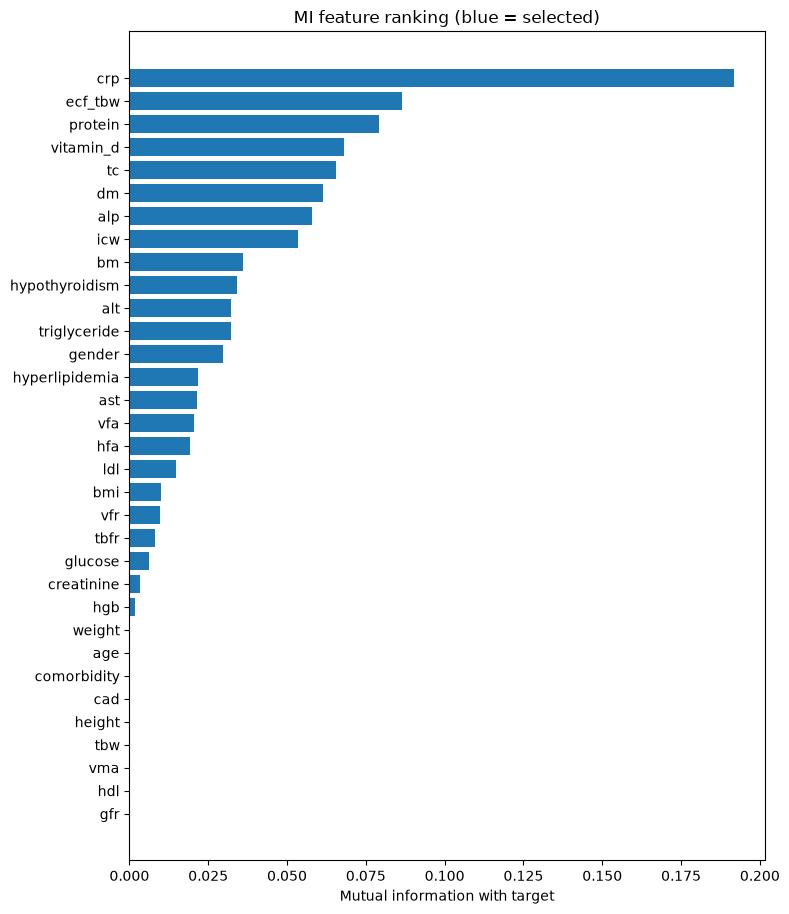

,MI
crp,0.1919
ecf_tbw,0.0865
protein,0.0792
vitamin_d,0.0681
tc,0.0655
dm,0.0614
alp,0.0579
icw,0.0536
bm,0.0361
hypothyroidism,0.0342


In [18]:
discrete_mask = [c in cat_cols for c in Xtr.columns]

mi = mutual_info_classif(Xtr, y_train, discrete_features=discrete_mask,
                         n_neighbors=3, random_state=RANDOM_STATE)
mi_s = pd.Series(mi, index=Xtr.columns).sort_values(ascending=False)

if MI_TOP_K is None:
    selected = mi_s[mi_s > 0].index.tolist()
else:
    selected = mi_s.head(MI_TOP_K).index.tolist()

print(f"Selected {len(selected)} of {Xtr.shape[1]} features")

plt.figure(figsize=(8, max(4, 0.28 * len(mi_s))))
colors = ["tab:blue" if f in selected else "lightgray" for f in mi_s.index]
plt.barh(mi_s.index[::-1], mi_s.values[::-1], color=colors[::-1])
plt.xlabel("Mutual information with target")
plt.title("MI feature ranking (blue = selected)")
plt.tight_layout(); plt.show()

mi_s.round(4).to_frame("MI")

In [19]:
Xtr_sel, Xte_sel = Xtr[selected], Xte[selected]
cat_idx = [i for i, c in enumerate(selected) if c in cat_cols]   # for CatBoost

## 7. Models and hyper-parameter search

Randomized search with stratified 5-fold CV on the training set. Scoring uses weighted F1 (works for binary and multi-class).

In [20]:
cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
SCORING = "f1_weighted"
binary = n_classes == 2

xgb_kwargs = dict(objective="binary:logistic", eval_metric="logloss") if binary \
    else dict(objective="multi:softprob", eval_metric="mlogloss")

models = {
    "Random Forest": (
        RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
        {"n_estimators": [200, 300, 500, 800],
         "max_depth": [None, 4, 6, 8, 12],
         "min_samples_split": [2, 5, 10],
         "min_samples_leaf": [1, 2, 4],
         "max_features": ["sqrt", "log2", 0.5],
         "class_weight": [None, "balanced"]}),
    "XGBoost": (
        XGBClassifier(random_state=RANDOM_STATE, n_jobs=-1, tree_method="hist", **xgb_kwargs),
        {"n_estimators": [200, 300, 500, 800],
         "max_depth": [3, 4, 5, 6, 8],
         "learning_rate": [0.01, 0.03, 0.05, 0.1, 0.2],
         "subsample": [0.6, 0.8, 1.0],
         "colsample_bytree": [0.6, 0.8, 1.0],
         "min_child_weight": [1, 3, 5],
         "gamma": [0, 0.1, 0.3],
         "reg_lambda": [0.5, 1, 2, 5]}),
    "CatBoost": (
        CatBoostClassifier(random_seed=RANDOM_STATE, verbose=0, thread_count=-1),
        {"iterations": [200, 400, 600],
         "depth": [3, 4, 6, 8],
         "learning_rate": [0.01, 0.03, 0.05, 0.1],
         "l2_leaf_reg": [1, 3, 5, 9],
         "bagging_temperature": [0, 0.5, 1]}),
}

searches = {}
for name, (est, grid) in models.items():
    print(f"Tuning {name} ...")
    rs = RandomizedSearchCV(est, grid, n_iter=N_ITER, scoring=SCORING, cv=cv,
                            random_state=RANDOM_STATE, n_jobs=1, refit=True, verbose=0)
    rs.fit(Xtr_sel, y_train)
    searches[name] = rs
    print(f"  best CV {SCORING}: {rs.best_score_:.4f}")
    print(f"  best params: {rs.best_params_}")

Tuning Random Forest ...


c:\Users\Hameed Computers\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Hameed Computers\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Hameed Computers\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib wor

  best CV f1_weighted: 0.7902
  best params: {'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': 'log2', 'max_depth': None, 'class_weight': 'balanced'}
Tuning XGBoost ...
  best CV f1_weighted: 0.7635
  best params: {'subsample': 0.6, 'reg_lambda': 1, 'n_estimators': 800, 'min_child_weight': 1, 'max_depth': 5, 'learning_rate': 0.05, 'gamma': 0.1, 'colsample_bytree': 1.0}
Tuning CatBoost ...
  best CV f1_weighted: 0.7660
  best params: {'learning_rate': 0.1, 'l2_leaf_reg': 3, 'iterations': 400, 'depth': 8, 'bagging_temperature': 0}


## 8. Evaluation on the 20% test set

In [21]:
rows, probas = [], {}
for name, rs in searches.items():
    model = rs.best_estimator_
    pred = model.predict(Xte_sel)
    proba = model.predict_proba(Xte_sel)
    probas[name] = proba
    auc = roc_auc_score(y_test, proba[:, 1]) if binary \
        else roc_auc_score(y_test, proba, multi_class="ovr", average="weighted")
    rows.append({"Model": name,
                 "Accuracy": accuracy_score(y_test, pred),
                 "Recall (weighted)": recall_score(y_test, pred, average="weighted"),
                 "F1 (weighted)": f1_score(y_test, pred, average="weighted"),
                 "ROC-AUC": auc,
                 "CV F1": rs.best_score_})

results = pd.DataFrame(rows).set_index("Model").round(4).sort_values("F1 (weighted)", ascending=False)
results

,Accuracy,Recall (weighted),F1 (weighted),ROC-AUC,CV F1
Model,,,,,
XGBoost,0.7969,0.7969,0.7964,0.8779,0.7635
CatBoost,0.7656,0.7656,0.7651,0.8340,0.7660
Random Forest,0.7656,0.7656,0.7642,0.8398,0.7902


In [22]:
best_name = results.index[0]
print("Best model on test set:", best_name)
best_model = searches[best_name].best_estimator_
print(classification_report(y_test, best_model.predict(Xte_sel), target_names=class_names, digits=4))

Best model on test set: XGBoost
              precision    recall  f1-score   support

           0     0.7714    0.8438    0.8060        32
           1     0.8276    0.7500    0.7869        32

    accuracy                         0.7969        64
   macro avg     0.7995    0.7969    0.7964        64
weighted avg     0.7995    0.7969    0.7964        64



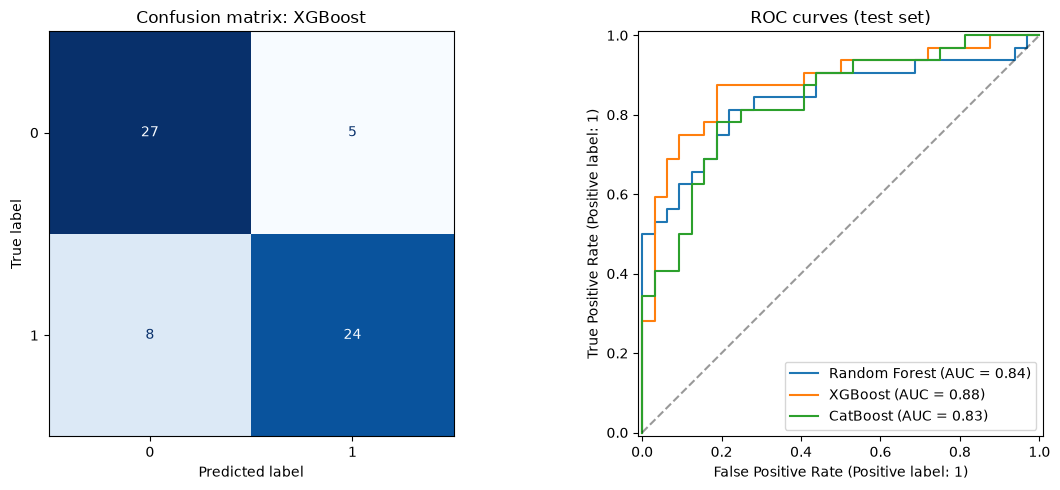

In [23]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay(confusion_matrix(y_test, best_model.predict(Xte_sel)),
                       display_labels=class_names).plot(ax=ax[0], cmap="Blues", colorbar=False)
ax[0].set_title(f"Confusion matrix: {best_name}")

if binary:
    for name, p in probas.items():
        RocCurveDisplay.from_predictions(y_test, p[:, 1], name=name, ax=ax[1])
    ax[1].plot([0, 1], [0, 1], "k--", alpha=0.4)
    ax[1].set_title("ROC curves (test set)")
else:
    ax[1].axis("off")
plt.tight_layout(); plt.show()

## 9. Feature importance of the best model

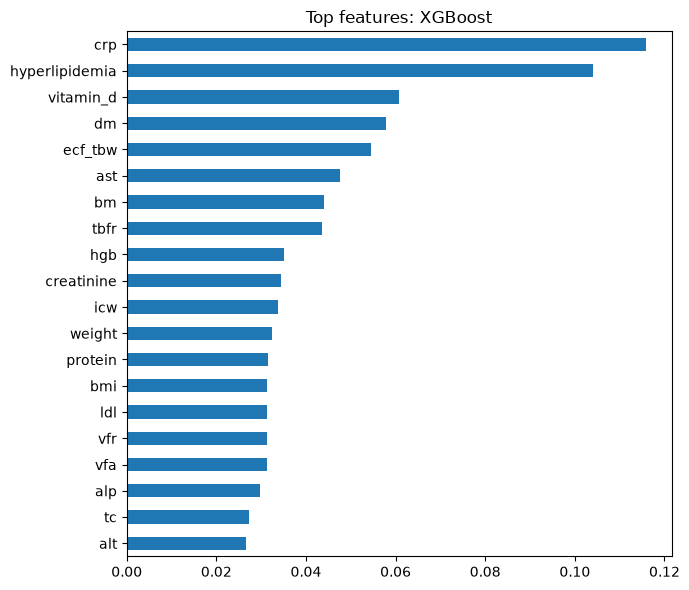

In [24]:
imp = pd.Series(best_model.feature_importances_, index=selected).sort_values()
imp.tail(20).plot.barh(figsize=(7, 6), title=f"Top features: {best_name}")
plt.tight_layout(); plt.show()

## Notes

- Mutual information, imputation and encoding are all **fit on the training data only**; the test set is touched once, at evaluation.
- Reported numbers will differ from any published values unless the dataset, preprocessing, seed and search space match exactly. Use `results` above for your own metrics.
- With ~300 rows, a 20% test set has about 60 samples, so each metric has wide uncertainty. Consider repeated stratified CV or bootstrapped confidence intervals when comparing models.
- Recall and F1 here are **weighted** averages (for a binary problem, weighted recall equals accuracy, which is why those two numbers are usually so close).